Telco Customer Churn Analysis

1. Introduction

Customer churn refers to the situation in which customers discontinue using a company's services. Understanding customer churn is important for identifying customer behavior patterns, improving customer retention, and supporting data-driven business decisions.

This project explores customer churn in a telecommunications company using the Telco Customer Churn dataset. The analysis focuses on identifying patterns and relationships between customer characteristics, subscribed services, billing information, contract types, and churn status.

The goal is to understand which customer groups have higher churn rates and identify potential areas where the company could improve customer retention.

2. Project Objectives

The main objectives of this analysis are:

* Understand the distribution of customer churn.
* Examine customer demographics and account characteristics.
* Analyze churn rates across different contract types and subscribed services.
* Investigate the relationships between customer tenure, monthly charges, total charges, and churn.
* Identify customer segments associated with higher churn rates.
* Summarize the key findings and provide actionable recommendations for improving customer retention.

3. Dataset Overview

The dataset contains customer-level information from a telecommunications company. Each row represents a customer, and the columns describe customer demographics, account information, subscribed services, billing details, and churn status.

The dataset contains 7,043 customer records and 21 columns.

The target variable for this analysis is Churn, which indicates whether a customer has left the company.

* Churn = Yes: The customer has left the company.
* Churn = No: The customer has remained with the company.

The dataset includes numerical variables, such as tenure, MonthlyCharges, and TotalCharges, as well as categorical variables, such as Contract, InternetService, PaymentMethod, and PaperlessBilling.

4. Analysis Methodology

The exploratory data analysis (EDA) follows these steps:

1. Examine the distribution of the target variable, Churn.
2. Calculate churn rates across categorical variables.
3. Compare numerical variables between customers who churned and those who remained.
4. Examine correlations between numerical variables and churn.
5. Use visualizations to identify patterns and differences between customer groups.
6. Summarize the findings and develop data-driven recommendations.

The analysis uses Python, Pandas, NumPy, Matplotlib, and Seaborn.

In [83]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [84]:
df=pd.read_csv("../data/cleaned_Telco-Customer-Churn.csv")

In [85]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [86]:
df.shape

(7043, 21)

In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [88]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [89]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn Distribution

In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
churn_counts=df["Churn"].value_counts()
churn_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

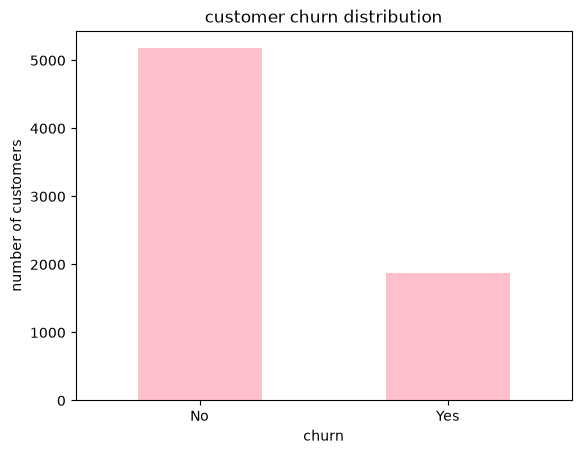

In [92]:
churn_counts.plot(kind="bar",color="pink")
plt.title("customer churn distribution")
plt.xlabel("churn")
plt.ylabel("number of customers")
plt.xticks(rotation=0)
plt.show()

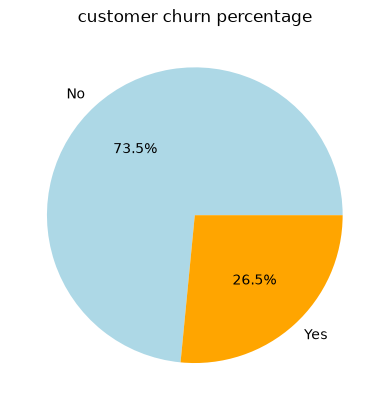

In [93]:
churn_counts.plot(kind="pie",autopct="%1.1f%%",colors=["lightblue","orange"])
plt.title("customer churn percentage")
plt.ylabel("")
plt.show()

In [94]:
print(df.groupby("Churn")["tenure"].mean())

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


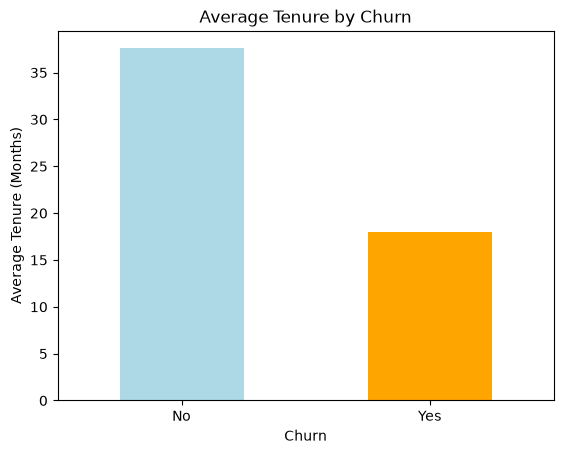

In [95]:
df.groupby("Churn")["tenure"].mean().plot(kind="bar",color=["lightblue","orange"])
plt.title("Average Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation=0)
plt.show()

In [96]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

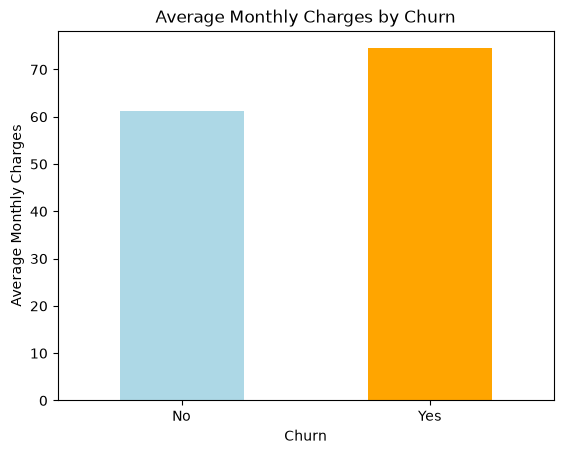

In [97]:
df.groupby("Churn")["MonthlyCharges"].mean().plot(kind="bar",color=["lightblue","orange"])
plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.show()

In [98]:
df[["tenure","MonthlyCharges"]].corr()

,tenure,MonthlyCharges
tenure,1.0000,0.2479
MonthlyCharges,0.2479,1.0000


In [99]:
df["Churn_Encoded"]=df["Churn"].map({
                      "No":0,
                      "Yes":1
                      })

In [100]:
df[["Churn_Encoded","MonthlyCharges"]].corr()

,Churn_Encoded,MonthlyCharges
Churn_Encoded,1.000000,0.193356
MonthlyCharges,0.193356,1.000000


In [101]:
pd.crosstab(df["gender"],df["Churn"])

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [102]:
pd.crosstab(df["gender"],
           df["Churn"],
           normalize="index")*100

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


In [103]:
df.groupby(["gender","Churn"])["MonthlyCharges"].mean()

gender  Churn
Female  No       61.664908
        Yes      74.812087
Male    No       60.876914
        Yes      74.066989
Name: MonthlyCharges, dtype: float64

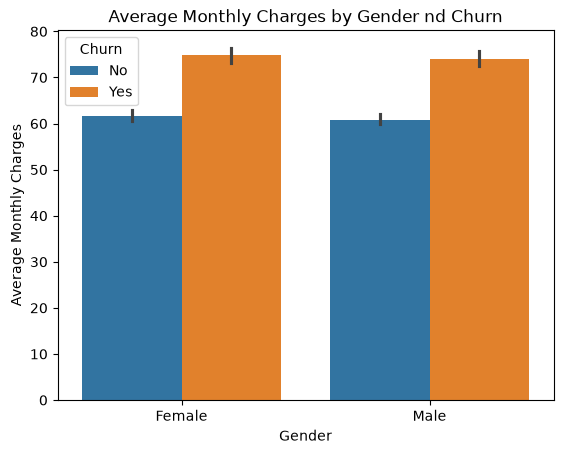

In [104]:
sns.barplot(data=df,
            x="gender",
            y="MonthlyCharges",
            hue="Churn"
            )

plt.title("Average Monthly Charges by Gender nd Churn")
plt.xlabel("Gender")
plt.ylabel("Average Monthly Charges")
plt.show()


In [105]:
pd.crosstab(df["Contract"],df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [106]:
pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


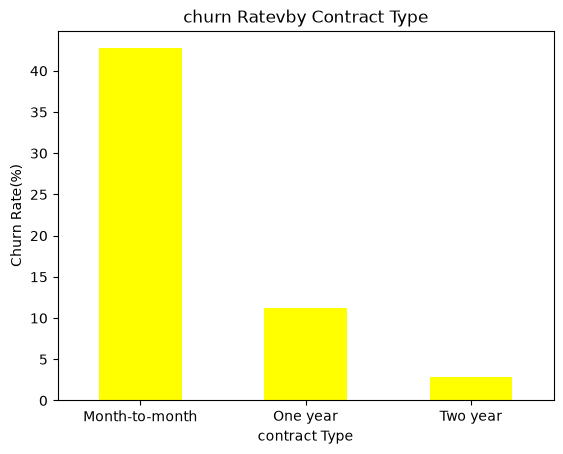

In [107]:
churn_by_contract=pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100
churn_by_contract["Yes"].plot(kind="bar",color="yellow")
plt.title("churn Ratevby Contract Type")
plt.xlabel("contract Type")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=0)
plt.show()

In [108]:
pd.crosstab(df["SeniorCitizen"],df["Churn"],normalize="index")*100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


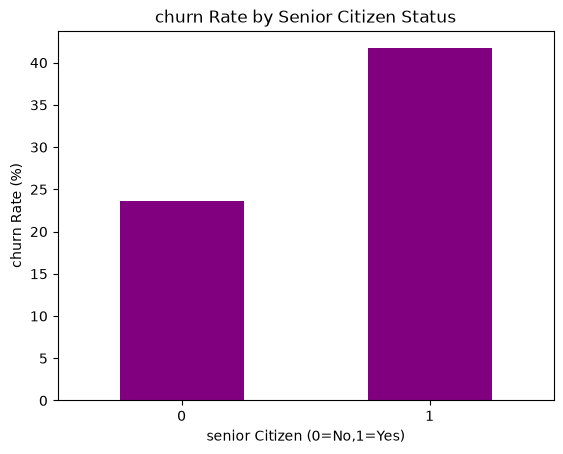

In [109]:
churn_by_senior=pd.crosstab(df["SeniorCitizen"],df["Churn"],normalize="index")*100
churn_by_senior["Yes"].plot(kind="bar",color="purple")
plt.title("churn Rate by Senior Citizen Status")
plt.xlabel("senior Citizen (0=No,1=Yes)")
plt.ylabel("churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [110]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [111]:
pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


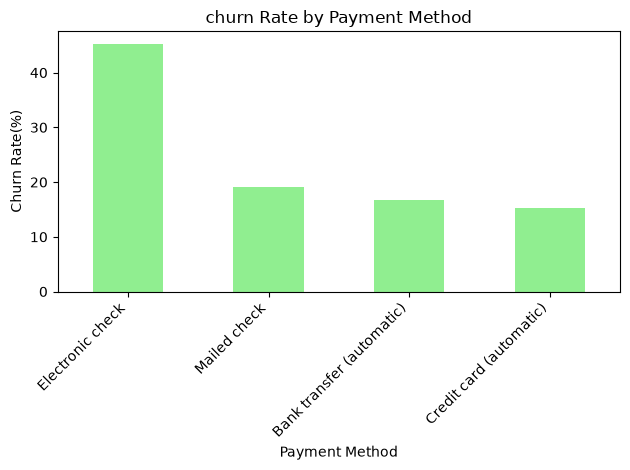

In [112]:
churn_by_payment=pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100
churn_by_payment["Yes"].sort_values(ascending=False).plot(kind="bar",color="lightgreen")
plt.title("churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [113]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [114]:
pd.crosstab(df["InternetService"],df["Churn"],normalize="index")*100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


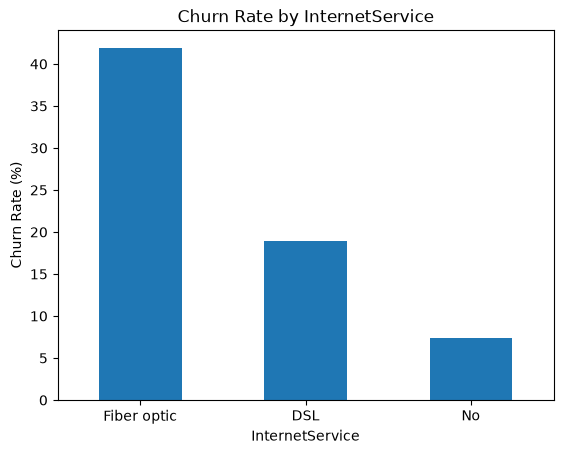

In [115]:
churn_by_InternetService=pd.crosstab(df["InternetService"],df["Churn"],normalize="index")*100
churn_by_InternetService["Yes"].sort_values(ascending=False).plot(kind="bar")
plt.title("Churn Rate by InternetService")
plt.xlabel("InternetService")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [116]:
df["PhoneService"].value_counts()

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

In [117]:
pd.crosstab(df["PhoneService"],df["Churn"],normalize="index")*100

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


In [118]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [119]:
pd.crosstab(df["OnlineSecurity"],df["Churn"],normalize="index")*100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


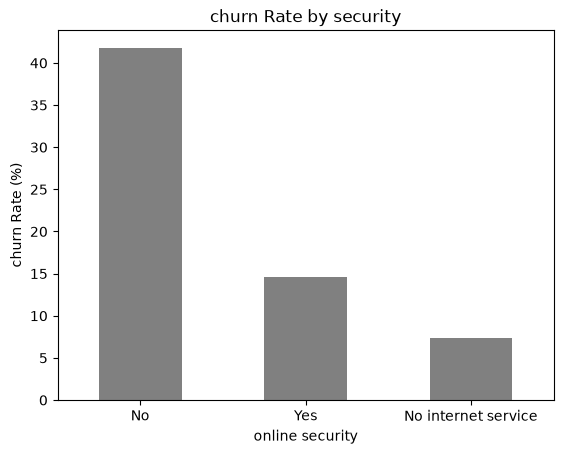

In [120]:
churn_by_security=pd.crosstab(df["OnlineSecurity"],df["Churn"],normalize="index")*100
churn_by_security["Yes"].sort_values(ascending=False).plot(kind="bar",color="gray")
plt.title("churn Rate by security")
plt.xlabel("online security")
plt.ylabel("churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [121]:
df["OnlineBackup"].value_counts()

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [122]:
pd.crosstab(df["OnlineBackup"],df["Churn"],normalize="index")*100

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


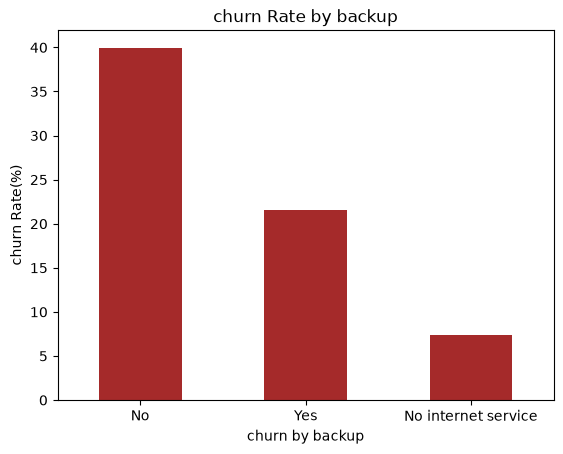

In [123]:
churn_by_backup=pd.crosstab(df["OnlineBackup"],df["Churn"],normalize="index")*100
churn_by_backup["Yes"].sort_values(ascending=False).plot(kind="bar",color="brown")
plt.title("churn Rate by backup")
plt.xlabel("churn by backup")
plt.ylabel("churn Rate(%)")
plt.xticks(rotation=0)
plt.show()

In [124]:
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [125]:
pd.crosstab(df["TechSupport"],df["Churn"],normalize="index")*100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


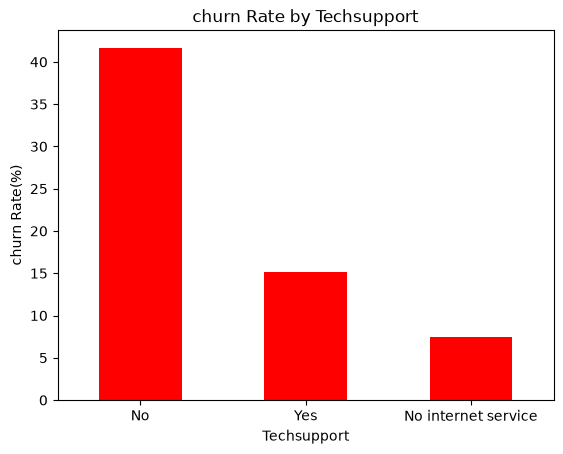

In [126]:
churn_by_support=pd.crosstab(df["TechSupport"],df["Churn"],normalize="index")*100
churn_by_support["Yes"].sort_values(ascending=False).plot(kind="bar",color="red")
plt.title("churn Rate by Techsupport")
plt.xlabel("Techsupport")
plt.ylabel("churn Rate(%)")
plt.xticks(rotation=0)
plt.show()


In [127]:
df["StreamingTV"].value_counts()

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

In [128]:
pd.crosstab(df["StreamingTV"],df["Churn"],normalize="index")*100

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


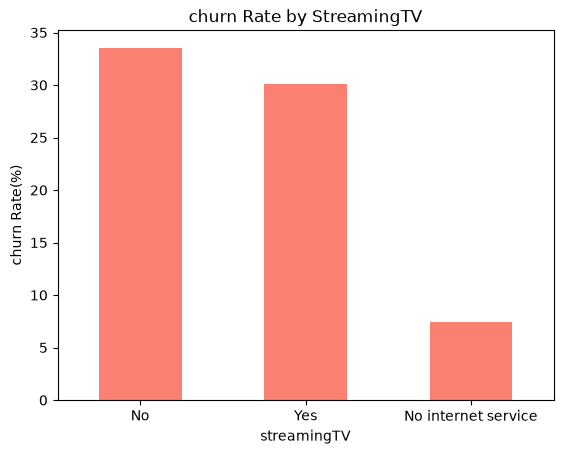

In [129]:
churn_by_tv=pd.crosstab(df["StreamingTV"],df["Churn"],normalize="index")*100
churn_by_tv["Yes"].sort_values(ascending=False).plot(kind="bar",color="salmon")
plt.title("churn Rate by StreamingTV")
plt.xlabel("streamingTV")
plt.ylabel("churn Rate(%)")
plt.xticks(rotation=0)
plt.show()


In [130]:
df["StreamingMovies"].value_counts()

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

In [131]:
pd.crosstab(df["StreamingMovies"],df["Churn"],normalize="index")*100

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


In [132]:
df["PaperlessBilling"].value_counts()

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

In [133]:
pd.crosstab(df["PaperlessBilling"],df["Churn"],normalize="index")*100

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


In [134]:
df["Partner"].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

In [135]:
pd.crosstab(df["Partner"],df["Churn"],normalize="index")*100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


In [136]:
df["Dependents"].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

In [137]:
pd.crosstab(df["Dependents"],df["Churn"],normalize="index")*100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


In [138]:
df["MultipleLines"].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [139]:
pd.crosstab(df["MultipleLines"],df["Churn"],normalize="index")*100

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


In [140]:
df.groupby("Churn")[["tenure","MonthlyCharges","TotalCharges"]].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


In [141]:
df.corr(numeric_only=True)["Churn_Encoded"].drop("Churn_Encoded").sort_values()

tenure           -0.352229
TotalCharges     -0.198324
SeniorCitizen     0.150889
MonthlyCharges    0.193356
Name: Churn_Encoded, dtype: float64

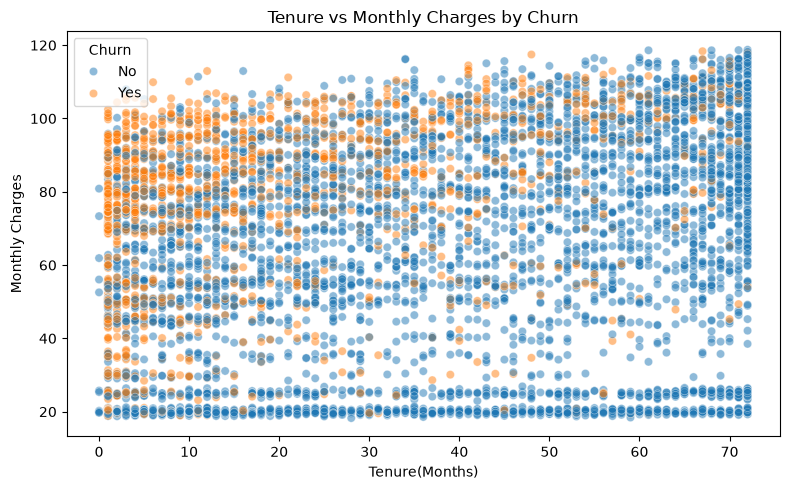

In [142]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.5
)
plt.title("Tenure vs Monthly Charges by Churn")
plt.xlabel("Tenure(Months)")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [143]:
churn_summary=(pd.crosstab(df["Contract"],df["Churn"],normalize="index"))*100
churn_summary=churn_summary.sort_values(
    by="Yes",
    ascending=False
)

churn_summary.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Key Findings

The exploratory data analysis revealed several patterns associated with customer churn:

* Contract Type: Customers with month-to-month contracts have a much higher churn rate than customers with one-year or two-year contracts.
* Customer Tenure: Customers who churn have a shorter average tenure than customers who remain with the company.
* Monthly Charges: Customers who churn have higher average monthly charges.
* Payment Method: Customers using electronic checks have a substantially higher churn rate than customers using other payment methods.
* Internet Service: Customers with fiber-optic internet have a higher churn rate than DSL customers.
* Online Security and Tech Support: Customers without online security or technical support have higher churn rates than customers who have these services.
* Paperless Billing: Customers using paperless billing have a higher churn rate than customers who do not.
* Dependents: Customers without dependents have a higher churn rate than customers with dependents.
* Senior Citizens: Senior citizens have a higher churn rate than non-senior customers.

In [144]:
key_findings=pd.DataFrame({
    "Factor":[
        "Contract",
        "Tenure",
        "MonthlyCharges",
        "PaperlessBilling",
        "Dependents"
    ],
    "key_Finding":[
        "Month_to_month contracts have the highest churn rate(42.71%)",
        "customers who churn have a lower average tenure (17.98 months)",
        "customers who chur have higher average monthly charges(74.44%)",
        "Paperless billing customers have a higher churn rate (33.57%)",
        "customers without dependents have a higher churn rate(31.28%)"
    ]
})

key_findings

,Factor,key_Finding
0,Contract,Month_to_month contracts have the highest chur...
1,Tenure,customers who churn have a lower average tenur...
2,MonthlyCharges,customers who chur have higher average monthly...
3,PaperlessBilling,Paperless billing customers have a higher chur...
4,Dependents,customers without dependents have a higher chu...


Overall Conclusions

1. Main Findings

The exploratory data analysis revealed several patterns associated with customer churn:

* Contract Type: Customers with month-to-month contracts have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
* Customer Tenure: Customers who churn have a shorter average tenure of 17.98 months, compared with 37.57 months for customers who remain.
* Monthly Charges: Customers who churn pay an average of 74.44 per month, compared with 61.27 for retained customers.
* Payment Method: Customers using electronic checks have a churn rate of 45.29%, substantially higher than customers using automatic payment methods.
* Internet Service: Fiber-optic customers have a churn rate of 41.89%, compared with 18.96% for DSL customers.
* Additional Services: Customers without online security or technical support have higher churn rates than customers who subscribe to these services.
* Customer Characteristics: Customers without dependents, senior citizens, and customers using paperless billing also show higher churn rates in this dataset.

 2. Potential Reasons for Customer Churn

The observed patterns suggest several possible explanations for customer churn:

1. Short-term contracts: Customers with month-to-month contracts may find it easier to leave the company because they have fewer long-term commitments.
2. Higher monthly costs: Higher monthly charges may contribute to customer dissatisfaction or encourage customers to consider alternatives.
3. Customer experience and service quality: The higher churn rate among fiber-optic customers may indicate a need to investigate service quality, pricing, reliability, and customer expectations.
4. Insufficient support services: Customers without online security or technical support may have different needs or may perceive less value in the company's services.
5. Customer engagement: The strong negative relationship between tenure and churn suggests that retaining new customers may be particularly important.

These explanations are hypotheses based on exploratory analysis. Further investigation is needed to determine the underlying causes of churn.

 3. Business Recommendations

Based on these findings, the company could consider the following actions:

* Develop retention strategies for customers with month-to-month contracts.
* Review pricing plans and investigate whether high monthly charges are associated with customer dissatisfaction.
* Examine complaints, service quality, and reliability among fiber-optic customers.
* Encourage suitable customers to consider longer-term contracts through transparent and appropriate incentives.
* Improve onboarding and follow-up support for new customers.
* Evaluate whether online security and technical support packages could provide additional value to customers.
* Investigate why electronic-check users have a higher churn rate and whether payment experience contributes to the difference.

 4. Limitations

This analysis identifies associations rather than proving causation. The results are based on descriptive statistics and exploratory analysis, without controlling for all potentially relevant factors. Additional statistical testing and predictive modeling would be needed to assess the importance of individual variables and predict which customers are most likely to churn.

5. Final Conclusion

Customer churn in this dataset is associated with several factors, particularly contract type, customer tenure, monthly charges, payment method, and internet service type. The highest observed churn rate occurs among customers with month-to-month contracts, while customers with shorter tenure are also more likely to leave.

The company should prioritize understanding the needs of new customers, reviewing the experience of customers with high monthly charges, and investigating the reasons behind the high churn rates among electronic-check and fiber-optic customers.


A combination of targeted retention strategies, improved customer support, and further data analysis could help the company better understand churn and develop more effective customer-retention policies.